# 1. Initial preparation, importing libraries and dataset

In [56]:
#data handling base
import pandas as pd
import numpy as np

#feature engineering
import re
import spacy 
from spacy.matcher import Matcher
from collections import Counter
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

#visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [62]:
#import dataset from csv file
df = pd.read_csv('twcs.csv', encoding='utf-8')

In [63]:
#column info
print(df.info())
print(f'\n{'*'* 40}\n')
print('number of NA values:')
print(df.isna().sum())
print(f'\n{'*'* 40}\n')
print('number of duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2811774 entries, 0 to 2811773
Data columns (total 7 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 131.4+ MB
None

****************************************

number of NA values:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64

****************************************

number of duplicate rows: 0


# 2. Data preparation and cleaning

In [64]:
#thread root:
def get_thread_root(tweet_id, parent_map):
    visited = set()
    while tweet_id in parent_map and tweet_id not in visited:
        visited.add(tweet_id)
        tweet_id = parent_map[tweet_id]
    return tweet_id

In [65]:
# pull all tweets belonging to those threads
parent_map = df.dropna(subset=['in_response_to_tweet_id']).set_index('tweet_id')['in_response_to_tweet_id'].to_dict()

df['thread_root'] = df['tweet_id'].apply(lambda x: get_thread_root(x, parent_map))

df['is_root'] = df['in_response_to_tweet_id'].isna()
df['is_end'] = df['response_tweet_id'].isna()

In [66]:
nonthreads = df[df['response_tweet_id'].isna() & df['in_response_to_tweet_id'].isna()]
nonthreads

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end


In [67]:
# All tweet IDs present in the dataset
parent_ids_in_data = set(df['tweet_id'])

# All parent references (drop NaN roots)
orphaned = df['in_response_to_tweet_id'].dropna()

# Boolean mask: True if parent is missing
mask = ~orphaned.isin(parent_ids_in_data)

orphan_count = mask.sum()
print(f'Orphaned tweets: {orphan_count} ({orphan_count/len(df)*100:.1f}%)')

# Create a dataframe of orphaned replies
df_orphans = df.loc[df['in_response_to_tweet_id'].isin(orphaned[mask])]
df_orphans.head()


Orphaned tweets: 3862 (0.1%)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
138,222,115760,True,Tue Oct 31 19:05:30 +0000 2017,@108162 @115761 @ATVIAssist tried that there w...,221,223.000,223.000,False,False
1035,1621,AzureSupport,False,Tue Oct 31 22:11:47 +0000 2017,@116051 Sorry to hear your having trouble. Cou...,1620,1622.000,1622.000,False,False
2817,3745,AmazonHelp,False,Tue Oct 31 22:36:29 +0000 2017,"@116616 David, te recomendamos no compartir in...",3744,3746.000,3746.000,False,False
2848,3777,116625,True,Tue Oct 31 22:53:05 +0000 2017,@AppleSupport I've also forced the app to clos...,3775,3779.000,3779.000,False,False
4082,5530,Ask_Spectrum,False,Tue Oct 31 23:08:39 +0000 2017,@117003 Please remove that from public. I have...,5529,5531.000,5531.000,False,False


In [68]:
orphan_thr = df_orphans['thread_root']
df = df.loc[~df['thread_root'].isin(orphan_thr)]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2795865 entries, 0 to 2811773
Data columns (total 10 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
 7   thread_root              float64
 8   is_root                  bool   
 9   is_end                   bool   
dtypes: bool(3), float64(2), int64(1), object(4)
memory usage: 178.6+ MB


In [69]:
df['thread_root'].nunique()

794335

In [70]:
#find root tweets
twroot = df['thread_root']

#get sample before applying to whole dataset, since 3 mil rows is long to compute.
sampled_roots = twroot.sample(n=20000, random_state=42)
#Instead of sampling dataset directly, I sampled roots, otherwise threads would be truncated

df_sample = df[df['thread_root'].isin(sampled_roots)].copy()
df_sample.head(5)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
81,160,ChipotleTweets,False,Tue Oct 31 22:06:55 +0000 2017,@115737 My apologies for that. Just sent you a...,NaN,161.000,163.000,False,True
82,161,115737,True,Tue Oct 31 21:59:25 +0000 2017,"@ChipotleTweets Tried, didn't work. How rude :/",160,162.000,163.000,False,False
83,162,ChipotleTweets,False,Tue Oct 31 19:51:00 +0000 2017,@115737 Give it a try. -Tara,161,163.000,163.000,False,False
84,163,115737,True,Tue Oct 31 19:43:47 +0000 2017,@ChipotleTweets can I dress up as myself and s...,162,NaN,163.000,True,False
276,383,Morrisons,False,Tue Oct 31 22:05:15 +0000 2017,"@115804 Hi there, sorry about that. Please DM ...",384,385.000,385.000,False,False


In [71]:
df_sample['created_at'] = pd.to_datetime(df_sample['created_at'], format='%a %b %d %H:%M:%S %z %Y', errors='coerce')
df_sample = df_sample.sort_values(['thread_root', 'created_at'])
df_sample['turn_index'] = df_sample.groupby('thread_root').cumcount()
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145117 entries, 84 to 2811652
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   tweet_id                 145117 non-null  int64              
 1   author_id                145117 non-null  object             
 2   inbound                  145117 non-null  bool               
 3   created_at               145117 non-null  datetime64[ns, UTC]
 4   text                     145117 non-null  object             
 5   response_tweet_id        96136 non-null   object             
 6   in_response_to_tweet_id  125640 non-null  float64            
 7   thread_root              145117 non-null  float64            
 8   is_root                  145117 non-null  bool               
 9   is_end                   145117 non-null  bool               
 10  turn_index               145117 non-null  int64              
dtypes: bool(3), date

In [72]:
valid_threads = (
    df_sample.groupby("thread_root")["inbound"]
    .apply(lambda x: x.any() and (~x).any())
)
valid_thread_ids = valid_threads[valid_threads].index

df_sample = df_sample[df_sample["thread_root"].isin(valid_thread_ids)]
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145115 entries, 84 to 2811652
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   tweet_id                 145115 non-null  int64              
 1   author_id                145115 non-null  object             
 2   inbound                  145115 non-null  bool               
 3   created_at               145115 non-null  datetime64[ns, UTC]
 4   text                     145115 non-null  object             
 5   response_tweet_id        96135 non-null   object             
 6   in_response_to_tweet_id  125639 non-null  float64            
 7   thread_root              145115 non-null  float64            
 8   is_root                  145115 non-null  bool               
 9   is_end                   145115 non-null  bool               
 10  turn_index               145115 non-null  int64              
dtypes: bool(3), date

# 3. Descriptive analysis

In [12]:
# pd.set_option('display.max_colwidth', 100)
# df_sample.style.set_properties(**{'text-align': 'left'})
# print(df_sample["text"].head(30))
# pd.set_option('display.max_colwidth', 30)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### 3.1 Check if sample doesn't differ from dataset


In [13]:
#comparing the percentage of root and end tweets in sample vs full dataset
nullratio = df_sample['in_response_to_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample root tweet percentage = ', nullratio,'%')

nullratio1 = df['in_response_to_tweet_id'].isna().sum() / df.shape[0] * 100
print('root tweet percentage        = ',nullratio1,'%')

nullratio2 = df_sample['response_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample end tweet percentage  = ',nullratio2,'%')

nullratio3 = df['response_tweet_id'].isna().sum() / df.shape[0] * 100
print('end tweet percentage         = ',nullratio3,'%')

sample root tweet percentage =  28.01669795197938 %
root tweet percentage        =  28.411064196590324 %
sample end tweet percentage  =  36.75090353850895 %
end tweet percentage         =  37.04552973766616 %


### 3.2 Author statistics

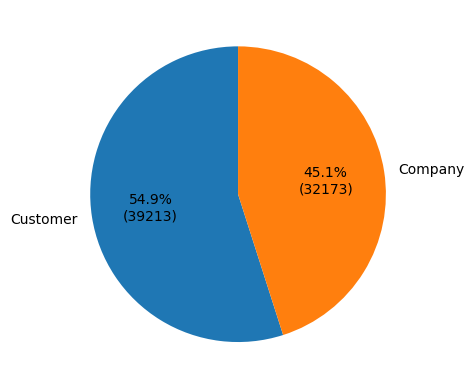

In [14]:
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n({val:d})'
    return my_autopct

inbound = df_sample['inbound'].value_counts()
plt.pie(x=inbound, labels=['Customer', 'Company'], autopct=make_autopct(inbound), startangle = 90)
plt.show()

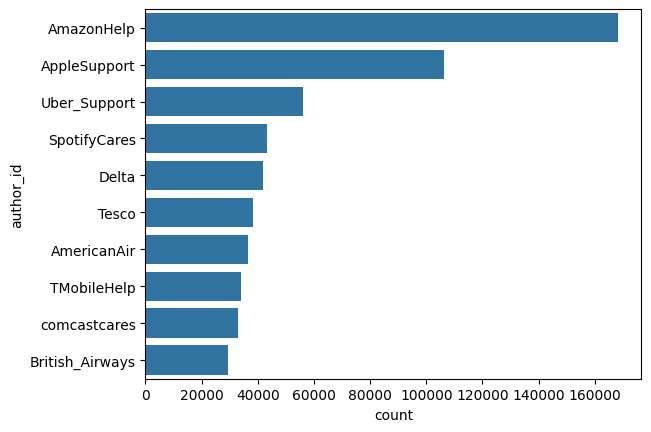

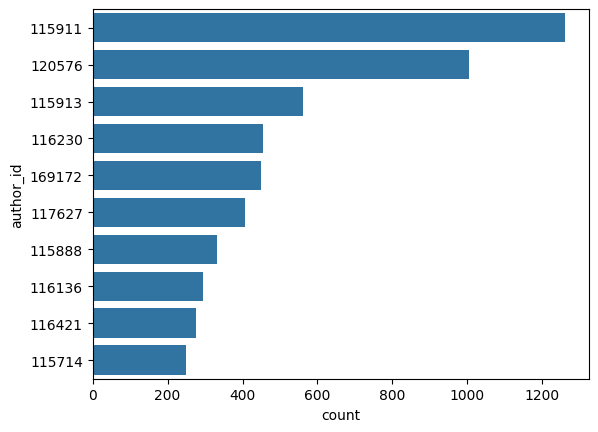

In [15]:
#filter only companies
companies = df[(df['inbound'] == False)]

#top 10 by count
order = companies['author_id'].value_counts().iloc[:10].index

#visualization
sns.countplot(companies['author_id'], order = order)
plt.show()

companies.head(5)

users = df[(df['inbound'] == True)]

order1 = users['author_id'].value_counts().iloc[:10].index

sns.countplot(users['author_id'], order = order1)
plt.show()

In [16]:
author_counts = (
    df.groupby('thread_root')['author_id']
    .nunique()
    .reset_index()
    .rename(columns={'author_id': 'n_distinct_authors'})
)

# Flag multi-party threads
author_counts['multi_party'] = author_counts['n_distinct_authors'] > 2

print(author_counts['n_distinct_authors'].value_counts().sort_index())
print(f"\nMulti-party threads: {author_counts['multi_party'].sum()}")

n_distinct_authors
1          62
2      737641
3       44197
4        6918
5        2088
        ...  
231         1
283         2
337         1
620         1
973         1
Name: count, Length: 120, dtype: int64

Multi-party threads: 56632


### 3.3 Text statistics

<function matplotlib.pyplot.show(close=None, block=None)>

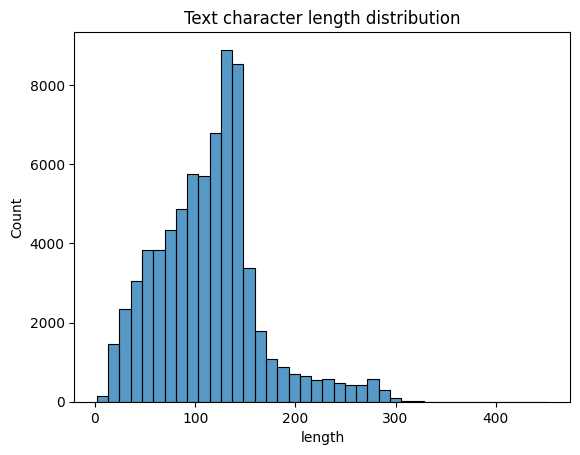

In [17]:
df_sample['chr_length'] = df_sample['text'].str.len()
sns.histplot(df_sample['chr_length'], bins = 40)

plt.title('Text character length distribution')
plt.xlabel('length')
plt.show

### 3.4 Thread statistics

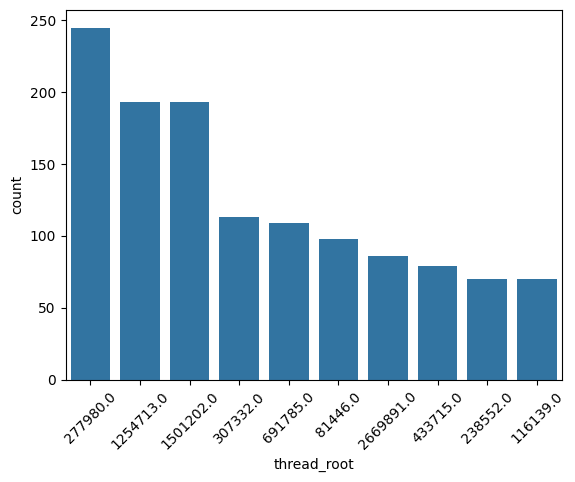

In [18]:
order2 = df_sample['thread_root'].value_counts().iloc[:10].index
sns.countplot(x = 'thread_root', data = df_sample, order = order2)
plt.xticks(rotation=45)
plt.show()

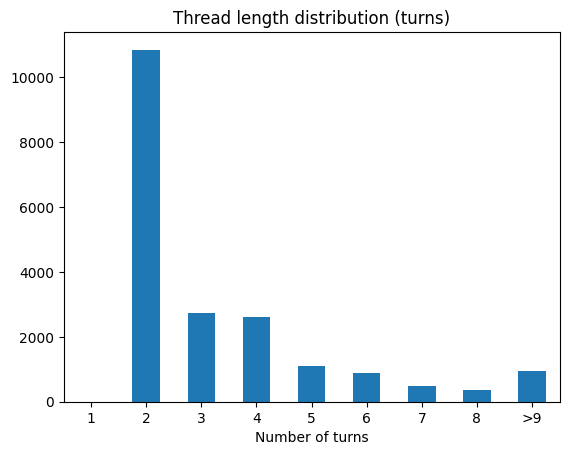

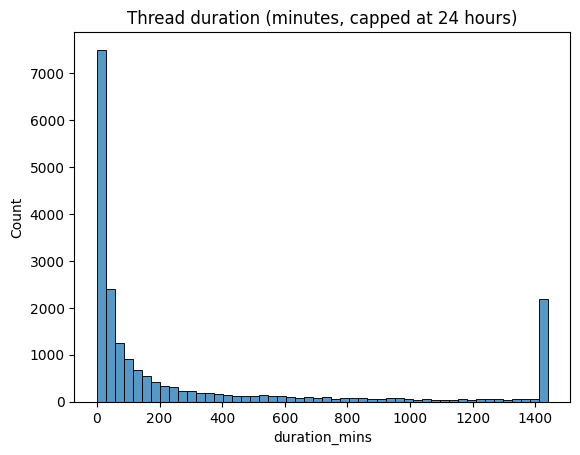

In [19]:
thread_stats = df_sample.groupby('thread_root').agg(
    turn_count=('tweet_id', 'count'),
    duration_mins=('created_at', lambda x: (x.max() - x.min()).total_seconds() / 60)
).reset_index()


bins1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, np.inf]
labels1 = ['1', '2', '3', '4', '5', '6', '7', '8', '>9']
thr = thread_stats['turn_count']


thr_bin = pd.cut(thr, bins=bins1, labels=labels1, right=False)
counts = thr_bin.value_counts().reindex(labels1)
counts.plot(kind='bar')

plt.title('Thread length distribution (turns)')
plt.xlabel('Number of turns')
plt.xticks(rotation = 0)
plt.show()

sns.histplot(thread_stats['duration_mins'].clip(upper=1440), bins=50)
plt.title('Thread duration (minutes, capped at 24 hours)')
plt.show()

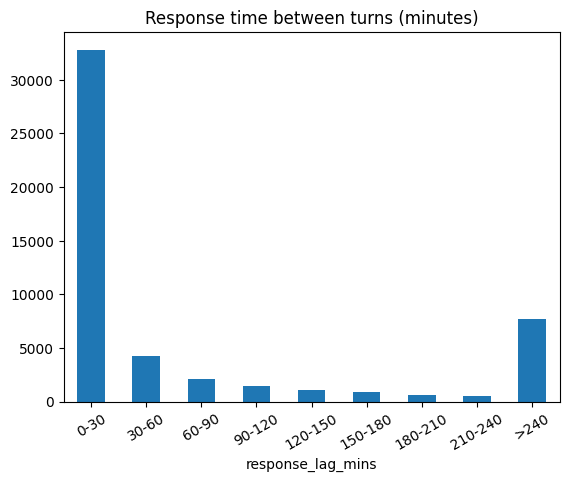

In [20]:
df_sample['response_lag_mins'] = df_sample.groupby('thread_root')['created_at'].diff().dt.total_seconds() / 60
lag = df_sample['response_lag_mins'].dropna()

bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, np.inf]
labels = ['0-30', '30-60', '60-90', '90-120', '120-150', '150-180', '180-210', '210-240', '>240']

lag_binned = pd.cut(lag, bins=bins, labels=labels, right=False)
counts = lag_binned.value_counts().reindex(labels)
counts.plot(kind='bar')
plt.title('Response time between turns (minutes)')
plt.xticks(rotation=30)
plt.show()

In [21]:
thread_stats.describe()


,thread_root,turn_count,duration_mins
count,20000.000,20000.000,20000.000
mean,1571450.710,3.569,1748.607
std,852423.772,4.248,27942.415
min,153.000,2.000,0.183
25%,838651.750,2.000,13.850
50%,1641082.000,2.000,59.850
75%,2291494.000,4.000,358.233
max,2987928.000,245.000,1738020.517


In [22]:
thre = thread_stats[(thread_stats['duration_mins'] > 2880)]
df_sample2 = df_sample[df_sample['thread_root'].isin(thre['thread_root'])]
df_sample2

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins
721,1260,115939,True,2017-10-30 01:02:34+00:00,@hulu_support @115940 my wife and I hate the...,1258,NaN,1260.000,True,False,0,126,NaN
717,1258,hulu_support,False,2017-10-31 22:28:55+00:00,@115939 Oh no! Any aspect about navigation tha...,1259,1260.000,1260.000,False,False,1,131,2726.350
718,1259,115939,True,2017-11-04 12:35:35+00:00,@hulu_support Getting to the lists of episodes...,1261,1258.000,1260.000,False,False,2,148,5166.667
719,1261,hulu_support,False,2017-11-06 23:42:12+00:00,@115939 Apologies for the difficulties! That w...,1262,1259.000,1260.000,False,False,3,136,3546.617
720,1262,115939,True,2017-11-07 00:20:46+00:00,@hulu_support Thanks,NaN,1261.000,1260.000,False,True,4,20,38.567
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2787967,2964467,817920,True,2017-10-19 08:10:46+00:00,@TfL please can you include hand rails for sho...,2964466,NaN,2964467.000,True,False,0,94,NaN
2787966,2964466,817920,True,2017-11-15 22:21:42+00:00,@TfL please can I have a follow up on this tweet?,2964465,2964467.000,2964467.000,False,False,1,49,39730.933
2787965,2964465,TfL,False,2017-11-29 20:37:30+00:00,"@817920 Hi Lucy, sorry for the delay respondin...",NaN,2964466.000,2964467.000,False,True,2,261,20055.800
2791579,2968140,818787,True,2017-11-27 13:18:19+00:00,@AirAsiaSupport hi! Is there an update on flig...,2968139,NaN,2968140.000,True,False,0,137,NaN


In [23]:
thre['duration_mins'].value_counts().sort_index(ascending=False)

duration_mins
1738020.517    1
1508275.800    1
1340663.100    1
1045114.017    1
1044831.183    1
              ..
2884.283       1
2883.683       1
2883.350       1
2882.800       1
2880.750       1
Name: count, Length: 1239, dtype: int64

In [24]:
df_sample2.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,9025.000,7785.000,9025.000,9025.000,9025.000,7785.000
mean,1264680.036,1183248.910,1117767.595,15.137,115.078,3850.371
std,850142.927,835138.368,821594.659,33.064,52.928,42427.830
min,1258.000,1258.000,1260.000,0.000,7.000,0.000
25%,477146.000,418921.000,332671.000,1.000,78.000,4.733
50%,1154175.000,1048312.000,969194.000,4.000,117.000,38.567
75%,1992321.000,1866124.000,1731810.000,11.000,141.000,954.567
max,2984490.000,2978305.000,2968140.000,244.000,452.000,1735649.400


In [25]:
df_sample.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,71386.000,51386.000,71386.000,71386.000,71386.000,51386.000
mean,1511908.284,1473994.360,1486951.485,3.813,113.582,680.577
std,858544.672,861554.008,862261.258,13.005,51.933,16569.955
min,152.000,153.000,153.000,0.000,2.000,0.000
25%,770095.000,734088.250,739402.000,0.000,78.000,3.000
50%,1520886.000,1453887.000,1483440.000,1.000,115.000,12.450
75%,2252562.750,2225360.000,2232701.000,3.000,139.000,78.800
max,2987928.000,2987928.000,2987928.000,244.000,452.000,1735649.400


In [26]:
with pd.option_context("display.max_rows", 1000):
    display(df_sample[df_sample['thread_root'] == 625855])

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins


In [27]:
thread_stats.describe()

,thread_root,turn_count,duration_mins
count,20000.000,20000.000,20000.000
mean,1571450.710,3.569,1748.607
std,852423.772,4.248,27942.415
min,153.000,2.000,0.183
25%,838651.750,2.000,13.850
50%,1641082.000,2.000,59.850
75%,2291494.000,4.000,358.233
max,2987928.000,245.000,1738020.517


In [28]:
(thread_stats['turn_count'] > 4).mean()

np.float64(0.19055)

### 3.5 Temporal statistics

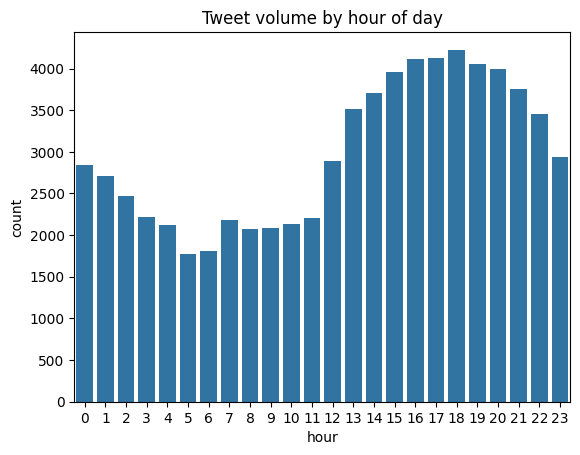

In [29]:
df_sample['hour'] = df_sample['created_at'].dt.hour
sns.countplot(x='hour', data=df_sample)
plt.title('Tweet volume by hour of day')
plt.show()

In [30]:
zero_lag = df_sample[(df_sample['response_lag_mins'] == 0) & (df_sample['inbound'] == True)]
with pd.option_context('display.max_colwidth', 100):
    display (df_sample[(df_sample['thread_root'].isin(zero_lag['thread_root']))].head(30))


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins,hour
301108,344909,198058,True,2017-10-08 01:16:34+00:00,@115873 I was charged twice for my Uber trip and your customer service isn’t emailing me back!!!...,344907,NaN,344909.000,True,False,0,135,NaN,1
301107,344907,Uber_Support,False,2017-10-08 01:20:15+00:00,@198058 We can definitely take a closer look! Please send us your email connected to your accoun...,"344906,344908",344909.000,344909.000,False,False,1,127,3.683,1
301106,344906,198058,True,2017-10-08 01:22:54+00:00,@Uber_Support what’s your email?,344905,344907.000,344909.000,False,False,2,32,2.650,1
706596,344908,198058,True,2017-10-08 01:22:54+00:00,@Uber_Support I sent u an email from my account,NaN,344907.000,344909.000,False,True,3,47,0.000,1
301105,344905,198058,True,2017-10-08 01:23:52+00:00,@Uber_Support I sent u a help request on my Uber app but haven’t gotten a response?,344904,344906.000,344909.000,False,False,4,83,0.967,1
301104,344904,Uber_Support,False,2017-10-08 02:04:34+00:00,@198058 Can you please DM us the email on your account so we can check on the status of your mes...,NaN,344905.000,344909.000,False,True,5,109,40.700,2
325484,372990,204391,True,2017-10-08 22:08:05+00:00,@AmericanAir never take this company !! it's the worse I know,372988,NaN,372990.000,True,False,0,61,NaN,22
325483,372988,AmericanAir,False,2017-10-08 22:46:41+00:00,@204391 We sense you're upset at us and we'd love to help. What's going on?,"372987,372989",372990.000,372990.000,False,False,1,75,38.600,22
740601,372989,204391,True,2017-10-08 22:48:19+00:00,@AmericanAir it's the second flight that is late in just one week. It's that normal ?,NaN,372988.000,372990.000,False,True,2,85,1.633,22
325482,372987,204391,True,2017-10-08 22:50:09+00:00,@AmericanAir If you want to help me so just give me an upgrade,372986,372988.000,372990.000,False,False,3,62,1.833,22


In [31]:
root_tweets = df_sample[df_sample['tweet_id'] == df_sample['thread_root']]
print(root_tweets['inbound'].value_counts())

inbound
True     19828
False      172
Name: count, dtype: int64


In [32]:
customer_roots = root_tweets[root_tweets['inbound'] == True]['tweet_id']
df_sample = df_sample[df_sample['thread_root'].isin(customer_roots)]

# 4. Linguistic Features

In [33]:
nlp = spacy.load("en_core_web_sm")


INBOUND_INTENT = {
    "cancel", "cancelled", "cancelling", "cancellation",
    "sue", "suing", "lawsuit", "lawyer", "legal",
    "ombudsman", "ofcom", "regulator", "watchdog",
    "chargeback", "refund", "reimbursement",
    "switching", "leaving", "elsewhere",
}

INBOUND_FRUSTRATION = {
    "unacceptable", "ridiculous", "disgusting", "outrageous",
    "appalling", "pathetic", "terrible", "horrible",
    "useless", "incompetent", "shameful", "shocking",
    "furious", "livid", "angry", "disgusted",
    "scam", "fraud", "lied", "liar", "cheated",
}

OUTBOUND_DEFLECTION = {
    "unable", "cannot", "policy", "procedure",
    "terms", "conditions", "unfortunately",
    "different", "department", "another", "team",
    "contact", "reach",
}

OUTBOUND_BUREAUCRATIC = {
    "kindly", "advised", "note", "patience",
    "understand", "appreciate", "bear",
    "investigate", "flag", "raise", "pass",
}

OUTBOUND_FORMAL_VOCAB = {
    "furthermore", "however", "subsequently", "regarding",
    "henceforth", "accordance", "hereby", "therein",
    "aforementioned", "notwithstanding", "whilst",
    "therefore", "thus", "hence", "wherein",
}

CONTRACTIONS = {
    "i'm", "we'll", "can't", "won't", "didn't", "we're",
    "you're", "it's", "that's", "there's", "don't", "isn't",
    "they're", "i'll", "i've", "you've", "we've",
}

INFORMAL_ABBREVIATIONS = {
    "dm", "asap", "fyi", "tbh", "imo",
    "btw", "ngl", "ty", "thx", "pls", "plz",
}

NEGATIVE_EMOJIS = {
    "😡", "😤", "🤬", "😠", "😒", "🙄", "💀", "😑", 
    "😫", "😩", "😣", "🖕", "😖", "😤"
}

NEGATION_TOKENS = {
    "not", "no", "never", "neither", "nor", "n't", "cant",       
    "won't", "wont", "didn't", "didnt", "don't", "dont",
    "isn't", "isnt", "wasn't", "wasnt", "couldn't", "couldnt", "shouldnt", "shouldn't"
}

In [34]:
def build_category_matchers(nlp):
    matchers = {}
    for name, termset in [
        ("inbound_intent",        INBOUND_INTENT),
        ("inbound_frustration",   INBOUND_FRUSTRATION),
        ("outbound_deflection",   OUTBOUND_DEFLECTION),
        ("outbound_bureaucratic", OUTBOUND_BUREAUCRATIC),
        ("outbound_formal_vocab", OUTBOUND_FORMAL_VOCAB),
    ]:
        m = Matcher(nlp.vocab)
        for term in termset:
            pattern = [{"LOWER": w} for w in term.split()]
            m.add(term, [pattern])
        matchers[name] = m
    return matchers

category_matchers = build_category_matchers(nlp)

In [35]:
def formality_score(doc) -> float:
    tokens = [t for t in doc if not t.is_space and not t.is_punct]
    if not tokens:
        return 50.0

    total = len(tokens)
    pos_counts = Counter(t.pos_ for t in tokens)

    noun = pos_counts.get("NOUN", 0) + pos_counts.get("PROPN", 0)
    adj  = pos_counts.get("ADJ", 0)
    prep = pos_counts.get("ADP", 0) 
    art  = pos_counts.get("DET", 0)  
    pron = pos_counts.get("PRON", 0)
    verb = pos_counts.get("VERB", 0) + pos_counts.get("AUX", 0)
    adv  = pos_counts.get("ADV", 0)
    intj = pos_counts.get("INTJ", 0)

    f = ((noun + adj + prep + art - pron - verb - adv - intj)
         / total * 100 + 100) / 2

    return round(f, 4)


In [ ]:
def informal_markers(doc, text: str) -> dict:
    tokens_lower = [t.lower_ for t in doc if not t.is_space]

    return {
        "contraction_count":  sum(1 for t in tokens_lower if t in CONTRACTIONS),
        "abbreviation_count": sum(1 for t in tokens_lower if t in INFORMAL_ABBREVIATIONS),
        "has_exclamation":    int("!" in text),
        "has_ellipsis":       int("..." in text),
    }

In [37]:
def extract_spacy_features(text: str, is_inbound: bool, doc=None) -> dict:
    if doc is None:
        doc = nlp(text)

    tokens       = [t for t in doc if not t.is_space]
    alpha_tokens = [t for t in tokens if t.is_alpha]

    token_count  = len(tokens)
    punct_count  = sum(1 for t in tokens if t.is_punct)
    upper_count  = sum(1 for t in alpha_tokens if t.text.isupper())
    caps_ratio   = upper_count / len(alpha_tokens) if alpha_tokens else 0.0

    # Negation 
    has_negation = int(any(t.lower_ in NEGATION_TOKENS for t in tokens))

    # POS counts 
    pos_counts = Counter(t.pos_ for t in tokens)
    verb_count = pos_counts.get("VERB", 0)
    adj_count  = pos_counts.get("ADJ", 0)
    noun_count = pos_counts.get("NOUN", 0)

    # NER 
    ner_counts  = Counter(ent.label_ for ent in doc.ents)
    has_money   = int(ner_counts.get("MONEY", 0) > 0)
    has_org     = int(ner_counts.get("ORG", 0) > 0)

    # Direction-exclusive features 
    if is_inbound:

        # category flags
        has_intent      = int(len(category_matchers["inbound_intent"](doc)) > 0)
        has_frustration = int(len(category_matchers["inbound_frustration"](doc)) > 0)
        has_deflection  = 0
        has_bureaucratic= 0

        # negative emoji
        has_negative_emoji = int(any(ch in NEGATIVE_EMOJIS for ch in text))

        # formality
        f_score             = None
        has_formal_vocab    = 0
        contraction_count   = 0
        abbreviation_count  = 0
        has_passive         = 0
        uses_we_not_i       = 0

    else:

        # Category flags
        has_intent      = 0
        has_frustration = 0
        has_deflection  = int(len(category_matchers["outbound_deflection"](doc)) > 0)
        has_bureaucratic= int(len(category_matchers["outbound_bureaucratic"](doc)) > 0)

        # Negative emoji
        has_negative_emoji = 0

        # Formality score (continuous)
        f_score = formality_score(doc)

        # Formal vocabulary flag
        has_formal_vocab = int(
            len(category_matchers["outbound_formal_vocab"](doc)) > 0
        )

        # Informal markers
        tokens_lower       = [t.lower_ for t in tokens]
        contraction_count  = sum(1 for t in tokens_lower if t in CONTRACTIONS)
        abbreviation_count = sum(1 for t in tokens_lower if t in INFORMAL_ABBREVIATIONS)

        # Passive voice
        has_passive = int(any(t.dep_ == "auxpass" for t in doc))

        pronoun_tokens = [t for t in doc
                          if t.pos_ == "PRON" and t.lower_ in {"i", "we"}]
        uses_we_not_i  = int(
            len(pronoun_tokens) > 0 and
            all(t.lower_ == "we" for t in pronoun_tokens)
        )

    return {
        # Surface
        "token_count":          token_count,
        "punct_count":          punct_count,
        "caps_ratio":           round(caps_ratio, 4),
        # Linguistic
        "has_negation":         has_negation,
        "verb_count":           verb_count,
        "adj_count":            adj_count,
        "noun_count":           noun_count,
        # NER
        "has_money_entity":     has_money,
        "has_org_entity":       has_org,
        # Inbound-exclusive
        "has_intent_term":      has_intent,
        "has_frustration_term": has_frustration,
        "has_negative_emoji":   has_negative_emoji,
        # Outbound-exclusive
        "has_deflection_term":   has_deflection,
        "has_bureaucratic_term": has_bureaucratic,
        "formality_score":       f_score,
        "has_formal_vocab":      has_formal_vocab,
        "contraction_count":     contraction_count,
        "abbreviation_count":    abbreviation_count,
        "has_passive":           has_passive,
        "uses_we_not_i":         uses_we_not_i,
    }

In [38]:
def extract_features_batch(df: pd.DataFrame,
                            text_col: str = "text",
                            inbound_col: str = "inbound",
                            batch_size: int = 256,
                            n_process: int = 1) -> pd.DataFrame:

    texts    = df[text_col].fillna("").tolist()
    inbounds = df[inbound_col].tolist()
    records  = []

    docs = nlp.pipe(texts, batch_size=batch_size, n_process=n_process)

    for doc, is_inbound in zip(docs, inbounds):
        records.append(
            extract_spacy_features(doc.text, is_inbound=bool(is_inbound), doc=doc)
        )

    features_df = pd.DataFrame(records, index=df.index)
    return pd.concat([df, features_df], axis=1)

In [39]:
print(f'spaCy extraction on {len(df_sample)} tweets')
df_ft1 = extract_features_batch(df_sample, text_col="text")

spaCy extraction on 69135 tweets


In [40]:
df_ft1

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,...,has_frustration_term,has_negative_emoji,has_deflection_term,has_bureaucratic_term,formality_score,has_formal_vocab,contraction_count,abbreviation_count,has_passive,uses_we_not_i
75,153,115734,True,2017-10-31 22:01:03+00:00,Happy Halloween! Since I'm too old to trick or...,152,NaN,153.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
74,152,ChipotleTweets,False,2017-10-31 22:10:33+00:00,"@115734 I mean, Boorito is basically the adult...",NaN,153.000,153.000,False,True,...,0,0,0,0,66.667,0,0,0,0,0
110,193,115748,True,2017-10-31 17:58:45+00:00,"‘Ere @marksandspencer, never mind avocado 🥑 - ...",192,NaN,193.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
109,192,marksandspencer,False,2017-10-31 21:48:52+00:00,@115748 We've let our team know we can do bett...,NaN,193.000,193.000,False,True,...,0,0,1,0,33.333,0,0,0,0,1
633,1163,115915,True,2017-10-31 22:20:14+00:00,T-Mobile So Bs My Internet Stop Working For 3 ...,1162,NaN,1163.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2811343,2987528,VirginAmerica,False,2017-10-31 21:48:00+00:00,@270982 Your awesome! Thanks for flying with u...,NaN,2987529.000,2987529.000,False,True,...,0,0,0,0,50.000,0,0,0,0,0
2811726,2987905,823855,True,2017-11-22 07:15:51+00:00,£250 train fare for my round trip to London to...,2987904,NaN,2987905.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
2811725,2987904,VirginTrains,False,2017-11-22 07:18:22+00:00,"@823855 Which service are you on, Fiona? ^CB",NaN,2987905.000,2987905.000,False,True,...,0,0,0,0,68.750,0,0,0,0,0
2811749,2987928,385866,True,2017-11-29 22:20:52+00:00,Ahh spent £120 yesterday and now Argos have th...,2987927,NaN,2987928.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0


In [41]:
cols = ['has_intent_term', 'has_frustration_term', 'has_deflection_term', 'has_bureaucratic_term', 'has_negative_emoji', 'has_money_entity', 'has_org_entity']
df_ft1[cols].apply(pd.Series.value_counts)

,has_intent_term,has_frustration_term,has_deflection_term,has_bureaucratic_term,has_negative_emoji,has_money_entity,has_org_entity
0,67746,67951,64648,66456,68233,67338,44255
1,1389,1184,4487,2679,902,1797,24880


In [42]:
df_ft1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 69135 entries, 75 to 2811748
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   tweet_id                 69135 non-null  int64              
 1   author_id                69135 non-null  object             
 2   inbound                  69135 non-null  bool               
 3   created_at               69135 non-null  datetime64[ns, UTC]
 4   text                     69135 non-null  object             
 5   response_tweet_id        43714 non-null  object             
 6   in_response_to_tweet_id  49307 non-null  float64            
 7   thread_root              69135 non-null  float64            
 8   is_root                  69135 non-null  bool               
 9   is_end                   69135 non-null  bool               
 10  turn_index               69135 non-null  int64              
 11  chr_length               69135

In [43]:
df_ft1[df_ft1['has_negative_emoji'] == 1]

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,...,has_frustration_term,has_negative_emoji,has_deflection_term,has_bureaucratic_term,formality_score,has_formal_vocab,contraction_count,abbreviation_count,has_passive,uses_we_not_i
682,1223,115929,True,2017-10-31 22:08:55+00:00,@SouthwestAir is down on the my account page 😑😑,1221,NaN,1223.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
6343,9444,117691,True,2017-10-31 23:46:11+00:00,iPhone X order cancelled. Email e-sig = bad UX...,9443,NaN,9444.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
21140,27243,121966,True,2017-10-31 17:51:42+00:00,"nahhh, bt why didn't i think of this? 🙄 @Gregg...",27242,NaN,27243.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
22210,28569,122253,True,2017-11-01 10:45:30+00:00,Feeling ever so slightly claustrophobic. This ...,28567,NaN,28569.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
25314,31991,123081,True,2017-11-01 12:21:35+00:00,Why do @115873 drivers insist on trying to dro...,31990,NaN,31991.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2798344,2974907,820453,True,2017-11-30 02:31:32+00:00,What is the point of @115821 prime when your p...,2974906,NaN,2974907.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2799612,2976146,360922,True,2017-11-16 04:05:56+00:00,ever since i updated my phone to the 11.1.1 ap...,2976145,NaN,2976146.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2799781,2976302,820837,True,2017-11-16 11:21:36+00:00,I need answers!!! @115858 this update has turn...,2976301,NaN,2976302.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2811125,2987309,813843,True,2017-11-21 22:25:09+00:00,@115714 y’all need to send me my phone already...,2987308,NaN,2987309.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0


# 5. Sentiment Features

In [45]:
def preprocess(text):
    text = re.sub(r"http\S+", "http", text)
    text = re.sub(r"@\w+", "@user", text)
    return text.strip()

In [ ]:
def score_batch(texts, batch_size=32):
    results = []

    for i in range(0, len(texts), batch_size):
        batch = [preprocess(t) for t in texts[i : i + batch_size]]

        inputs = tokenizer(
            batch,
            return_tensors="pt",
            truncation=True,
            max_length=128,
            padding=True 
        ).to(device)

        with torch.no_grad():
            logits = model(**inputs).logits

        probs = F.softmax(logits, dim=1).cpu().numpy()

        for row in probs:
            results.append({
                "sentiment_neg": round(float(row[0]), 4),
                "sentiment_neu": round(float(row[1]), 4),
                "sentiment_pos": round(float(row[2]), 4),
            })

        if i % 5000 == 0:
            print(f"  done {i}/{len(texts)}")

    return results

In [47]:
def score_tweets_batch(texts: list,
                        batch_size: int = 32,
                        max_length: int = 128) -> list:
    """
    Score a list of tweet strings.
    Returns a list of dicts with sentiment_neg, sentiment_neu, sentiment_pos.
    """
    results = []

    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]

        # Preprocess each tweet in the batch
        batch_processed = [preprocess_for_roberta(t) for t in batch]

        inputs = tokenizer(
            batch_processed,
            return_tensors="pt",
            truncation=True,
            max_length=max_length,
            padding=True,
        ).to(device)

        with torch.no_grad():
            logits = model(**inputs).logits

        # Softmax converts raw logits to probabilities
        probs = F.softmax(logits, dim=1).cpu().numpy()

        for row in probs:
            results.append({
                "sentiment_neg": round(float(row[0]), 4),
                "sentiment_neu": round(float(row[1]), 4),
                "sentiment_pos": round(float(row[2]), 4),
            })

        # Progress indicator — 69k tweets takes a few minutes on CPU
        if (i // batch_size) % 50 == 0:
            print(f"  Scored {min(i + batch_size, len(texts))}/{len(texts)} tweets...")

    return results

In [49]:
MODEL = "cardiffnlp/twitter-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = model.to(device)
model.eval()
print(f"running on: {device}")

# run on full dataset
texts  = df_ft1["text"].fillna("").tolist()
scores = score_batch(texts, batch_size=32)

scores_df      = pd.DataFrame(scores, index=df_ft1.index)
tweets_scored  = pd.concat([df_ft1, scores_df], axis=1)

# quick check - should see inbound tweets score higher on negative
print(tweets_scored.groupby("inbound")[["sentiment_neg", "sentiment_neu", "sentiment_pos"]].mean().round(3))

tweets_scored.to_csv("tweets_sentiment.csv", index=False)
print("saved -> tweets_sentiment.csv")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 20096.19it/s]


running on: cpu
  done 0/69135
  done 20000/69135
  done 40000/69135
  done 60000/69135
         sentiment_neg  sentiment_neu  sentiment_pos
inbound                                             
False            0.137          0.514          0.349
True             0.450          0.365          0.185
saved -> tweets_sentiment.csv


In [ ]:
out = tweets_scored[tweets_scored["inbound"] == False].copy()

print("--- high negative outbound ---")
print(out.nlargest(10, "sentiment_neg")[["text", "sentiment_neg"]].to_string())

print("\n--- outbound neg distribution ---")
print(out["sentiment_neg"].describe().round(3))
print("\noutbound tweets with neg > 0.5:", (out["sentiment_neg"] > 0.5).sum())
print("outbound tweets with neg > 0.3:", (out["sentiment_neg"] > 0.3).sum())

--- high negative outbound ---
                                                                                                                                                                                                                                                                             text  sentiment_neg
1236533                                                                                                                                                                                                 @272953 Hi, thanks for contacting us.  This doesn't sound good! :-(  *HML          0.963
179897                                                                                                                                                                            @166620 This doesn't sound good at all! How long have you been experiencing service issues? -JC          0.961
1616929                                                                                               

In [ ]:
inb = tweets_scored[tweets_scored["inbound"] == True].copy()

print("--- high negative inb ---")
print(inb.nlargest(10, "sentiment_neg")[["text", "sentiment_neg"]].to_string())
print("\n--- inb neg distribution ---")
print(inb["sentiment_neg"].describe().round(3))

print("\ninb tweets with neg > 0.5:", (inb["sentiment_neg"] > 0.5).sum())
print("inb tweets with neg > 0.3:", (inb["sentiment_neg"] > 0.3).sum())

--- high negative inb ---
                                                                                                                                                                                                                                       text  sentiment_neg
462830                                                                                                                              i am so tired being on the phone with @AmazonHelp customer care!!!!y'all useless and not helpful at all          0.985
457261    I fucking hate @115873 every single time I use It (which is almost every day) there is an issue either with the app glitching, the driver being crazy or unauthorized charges on my account. Customer service is BEYOND pathetic.          0.985
1545097                                                                                                                             I'm so disappointed in the horrible customer service I receieved at 2 @115911 stores this

In [55]:
tweets_scored["formality_score"] = tweets_scored["formality_score"].fillna(0.0)

# 6. Thread-level Feature Aggregation

In [ ]:
def get_slope(neg, turns):
    # slope of customer negative sentiment over the convo
    if len(neg) < 2:
        return 0.0
    return round(float(np.polyfit(turns, neg, 1)[0]), 4)

In [ ]:
def get_agent_sim(texts):
    # how similar are the agent replies to each other
    if len(texts) < 2:
        return 0.0
    try:
        tf  = TfidfVectorizer().fit_transform(texts)
        sim = cosine_similarity(tf)
        n   = sim.shape[0]
        vals = [sim[i][j] for i in range(n) for j in range(i+1, n)]
        return round(sum(vals) / len(vals), 4)
    except:
        return 0.0

In [79]:
rows = []

for tid, g in tweets_scored.groupby("thread_root"):
    inb = g[g["inbound"] == True].sort_values("turn_index")
    out = g[g["inbound"] == False].sort_values("turn_index")

    d = {}
    d["thread_root"] = tid
    d["turn_count"]  = len(g)
    d["inb_turns"]   = len(inb)
    d["out_turns"]   = len(out)

    # customer sentiment
    d["neg_ratio"]               = round(float((inb["sentiment_neg"] > 0.5).mean()), 4)
    d["inb_neg_mean"]            = round(float(inb["sentiment_neg"].mean()), 4)
    d["inb_neg_median"]          = round(float(inb["sentiment_neg"].median()), 4)
    d["inb_neg_max"]             = round(float(inb["sentiment_neg"].max()), 4)
    d["sentiment_trajectory"]    = get_slope(inb["sentiment_neg"].tolist(), inb["turn_index"].tolist())
    # company sentiment - mean and median bc mean gets pulled by outliers
    d["out_neg_mean"]            = round(float(out["sentiment_neg"].mean()), 4)
    d["out_neg_median"]          = round(float(out["sentiment_neg"].median()), 4)


    # customer escalation flags
    d["inb_intent_any"]          = int(inb["has_intent_term"].any())
    d["inb_frustration_any"]     = int(inb["has_frustration_term"].any())
    d["inb_neg_emoji_any"]       = int(inb["has_negative_emoji"].any())
    d["inb_negation_ratio"]      = round(float(inb["has_negation"].mean()), 4)
    d["inb_caps_mean"]           = round(float(inb["caps_ratio"].mean()), 4)
    d["inb_money_any"]           = int(inb["has_money_entity"].any())

    # company escalation flags
    d["out_deflection_any"]      = int(out["has_deflection_term"].any())
    d["out_bureaucratic_any"]    = int(out["has_bureaucratic_term"].any())
    d["out_abbrev_mean"]         = round(float(out["abbreviation_count"].mean()), 4)
    d["out_neu_mean"] = round(float(out["sentiment_neu"].mean()), 4)

    # company formality
    d["out_formality_mean"]      = round(float(out["formality_score"].mean()), 4)
    d["out_formal_vocab_any"]    = int(out["has_formal_vocab"].any())
    d["out_passive_ratio"]       = round(float(out["has_passive"].mean()), 4)
    d["out_contraction_mean"]    = round(float(out["contraction_count"].mean()), 4)
    d["out_we_ratio"]            = round(float(out["uses_we_not_i"].mean()), 4)

    # templated response detection
    d["agent_sim"] = get_agent_sim(out["text"].fillna("").tolist())

    # response time
    d["response_lag_mean"] = round(float(g["response_lag_mins"].mean()), 4)
    d["response_lag_max"]  = round(float(g["response_lag_mins"].max()), 4)

    root_hour = g.sort_values("turn_index").iloc[0]["hour"]
    d["root_hour"] = int(root_hour)
    
    rows.append(d)

df_threads = pd.DataFrame(rows)

print(f"tweets {len(tweets_scored)} -> threads {len(df_threads)}")
print(df_threads.describe().round(3))

df_threads.to_csv("threads_aggregated.csv", index=False)
print("saved")

tweets 69135 -> threads 19828
       thread_root  turn_count  inb_turns  out_turns  neg_ratio  inb_neg_mean  \
count    19828.000   19828.000  19828.000  19828.000  19828.000     19828.000   
mean   1571665.752       3.487      1.915      1.572      0.510         0.479   
std     852230.661       3.408      2.164      1.422      0.442         0.326   
min        153.000       2.000      1.000      1.000      0.000         0.001   
25%     838651.750       2.000      1.000      1.000      0.000         0.171   
50%    1641922.000       2.000      1.000      1.000      0.500         0.480   
75%    2290766.750       4.000      2.000      2.000      1.000         0.783   
max    2987928.000     245.000    149.000     96.000      1.000         0.985   

       inb_neg_median  inb_neg_max  sentiment_trajectory  out_neg_mean  ...  \
count       19828.000    19828.000             19828.000     19828.000  ...   
mean            0.477        0.579                -0.033         0.134  ...   
std

# 7. Proxy labels

# 8. Hypothesis Testing

# 9. Preprocessing

# 10. Model Training

# 11. Evaluation and Explainability

# 12. Results